In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import load_model
from sklearn.metrics import classification_report, confusion_matrix
from pathlib import Path

# ¡CRÍTICO! Redefinimos la operación matemática de ShuffleNetV2
# para que Keras sepa cómo reconstruir el modelo guardado.
def channel_shuffle(x):
    _, h, w, c = x.shape.as_list()
    x = tf.reshape(x, [-1, h, w, 2, c // 2])
    x = tf.transpose(x, [0, 1, 2, 4, 3])
    x = tf.reshape(x, [-1, h, w, c])
    return x

2026-10-05 14:01:57.792380: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-05 14:01:58.191808: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-05 14:01:59.404008: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# --- 1. CONFIGURACIÓN DE RUTAS ---
BASE_DIR = Path("../..")
DATA_DIR = BASE_DIR / "data" / "raw" / "waste_classification" / "test"
MODELS_DIR = BASE_DIR / "models"
FIGURES_DIR = BASE_DIR / "reports" / "figures"

# Creamos la carpeta de figuras por si no existe
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Apuntamos exactamente al archivo que acabamos de crear
MODEL_PATH = MODELS_DIR / "modelo_residuos_shufflenetV2_nativo.keras"

In [4]:
# --- 2. VERIFICACIÓN Y CARGA ---
if not DATA_DIR.exists():
    raise FileNotFoundError(f"No se encontraron los datos en: {DATA_DIR}")
if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No se encontró el modelo en: {MODEL_PATH}")

print(f"Cargando modelo desde: {MODEL_PATH}")

# Inyectamos nuestra función personalizada y desactivamos el modo seguro
model = load_model(
    MODEL_PATH,
    custom_objects={'channel_shuffle': channel_shuffle},
    safe_mode=False # <--- SOLUCIÓN AQUÍ
)
print("✅ Modelo ShuffleNetV2 cargado exitosamente en memoria.")

Cargando modelo desde: ../models/modelo_residuos_shufflenetV2_nativo.keras
✅ Modelo ShuffleNetV2 cargado exitosamente en memoria.


In [5]:
# --- 3. PREPARACIÓN DE DATOS (Set de Prueba) ---
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Sin Data Augmentation, el modelo evalúa las imágenes tal cual son
datagen = ImageDataGenerator()

print("Preparando imágenes de prueba...")
test_gen = datagen.flow_from_directory(
    str(DATA_DIR),
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False # OBLIGATORIO: False, para que el reporte empate correctamente
)

class_names = list(test_gen.class_indices.keys())
print(f"Clases a evaluar: {len(class_names)} -> {class_names}")

Preparando imágenes de prueba...
Found 4534 images belonging to 5 classes.
Clases a evaluar: 5 -> ['aluminio', 'carton', 'otros', 'plastico', 'vidrio']


In [6]:
# --- 4. EVALUACIÓN ESTÁNDAR ---
print("Evaluando métricas globales de ShuffleNetV2...")
loss, accuracy = model.evaluate(test_gen)

print(f"\nResultados de Evaluación:")
print(f"   Pérdida Matemática (Loss): {loss:.4f}")
print(f"   Precisión Real (Accuracy): {accuracy*100:.2f}%")

Evaluando métricas globales de ShuffleNetV2...


/home/jesus/Documentos/GitHub/EntrenamientoIA/.venv/lib/python3.12/site-packages/PIL/Image.py:1034: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
2026-10-05 14:05:53.061018: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f7e40003070 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-05 14:05:53.061045: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3050 Ti Laptop GPU, Compute Capability 8.6
2026-10-05 14:05:53.127026: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-05 14:05:53.781802: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 92501


  1/142 ━━━━━━━━━━━━━━━━━━━━ 17:46 8s/step - accuracy: 0.6875 - loss: 0.8850

I0000 00:00:1791230758.081619   12833 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


142/142 ━━━━━━━━━━━━━━━━━━━━ 29s 154ms/step - accuracy: 0.8130 - loss: 0.5635

Resultados de Evaluación:
   Pérdida Matemática (Loss): 0.5635
   Precisión Real (Accuracy): 81.30%


Generando predicciones individuales (esto puede tardar unos segundos)...
142/142 ━━━━━━━━━━━━━━━━━━━━ 23s 132ms/step


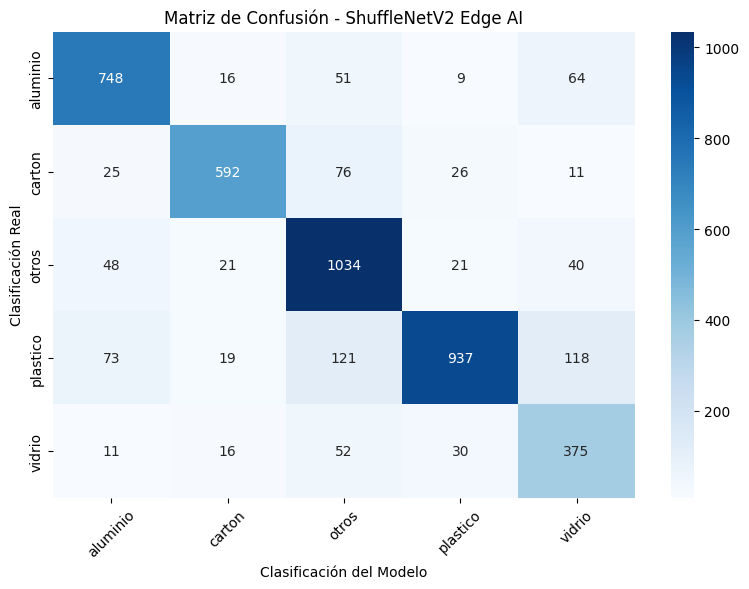


Desglose de Clasificación por Categoría:
              precision    recall  f1-score   support

    aluminio       0.83      0.84      0.83       888
      carton       0.89      0.81      0.85       730
       otros       0.78      0.89      0.83      1164
    plastico       0.92      0.74      0.82      1268
      vidrio       0.62      0.77      0.69       484

    accuracy                           0.81      4534
   macro avg       0.81      0.81      0.80      4534
weighted avg       0.83      0.81      0.81      4534



In [7]:
# --- 5. PREDICCIONES MULTICLASE ---
print("Generando predicciones individuales (esto puede tardar unos segundos)...")
predictions = model.predict(test_gen)
y_pred = np.argmax(predictions, axis=1) # Extrae la clase con más probabilidad
y_true = test_gen.classes               # La etiqueta real del archivo

# Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Matriz de Confusión - ShuffleNetV2 Edge AI')
plt.ylabel('Clasificación Real')
plt.xlabel('Clasificación del Modelo')
plt.xticks(rotation=45)
plt.tight_layout()

# Guardar y mostrar
save_path = FIGURES_DIR / "matriz_confusion_shufflenet.png"
plt.savefig(save_path, dpi=300)
plt.show()

# Reporte detallado de Precision, Recall y F1-Score
print("\nDesglose de Clasificación por Categoría:")
print(classification_report(y_true, y_pred, target_names=class_names))

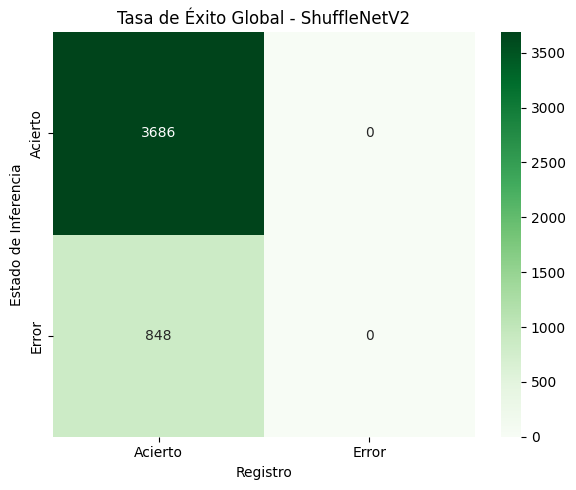


Resumen Ejecutivo:
  Evaluaciones totales : 4534
  Clasificaciones correctas : 3686 (81.30%)
  Falsos positivos/negativos: 848 (18.70%)


In [8]:
# --- 6. RENDIMIENTO BINARIO ---
y_true_bin = (y_true == y_pred).astype(int)
y_pred_bin = np.ones(len(y_pred), dtype=int)

cm_bin = confusion_matrix(y_true_bin, y_pred_bin, labels=[1, 0])

plt.figure(figsize=(6, 5))
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Acierto', 'Error'],
            yticklabels=['Acierto', 'Error'])
plt.title('Tasa de Éxito Global - ShuffleNetV2')
plt.ylabel('Estado de Inferencia')
plt.xlabel('Registro')
plt.tight_layout()
plt.show()

total = len(y_true)
correctos = np.sum(y_true == y_pred)
incorrectos = total - correctos

print(f"\nResumen Ejecutivo:")
print(f"  Evaluaciones totales : {total}")
print(f"  Clasificaciones correctas : {correctos} ({correctos/total*100:.2f}%)")
print(f"  Falsos positivos/negativos: {incorrectos} ({incorrectos/total*100:.2f}%)")


Extrayendo 5 ejemplos de fallos para análisis visual:


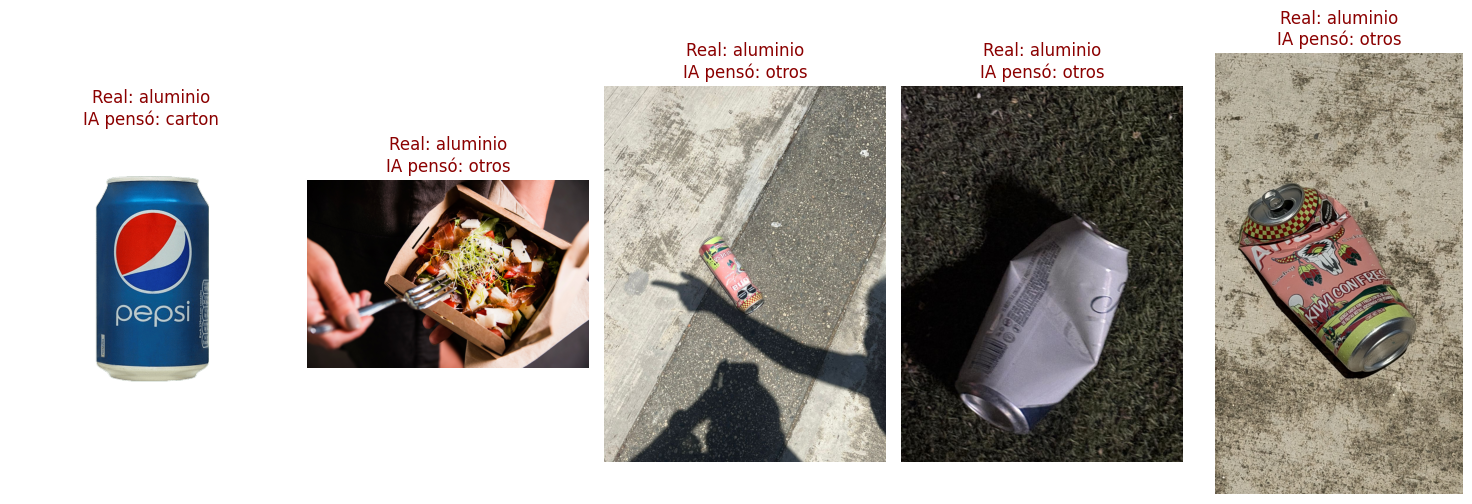

In [9]:
# --- 7. INSPECCIÓN VISUAL FORENSE ---
# Localizamos qué imágenes en específico "engañaron" a la red neuronal
errors = np.where(y_pred != y_true)[0]
num_errores_a_mostrar = min(5, len(errors))

if num_errores_a_mostrar > 0:
    print(f"\nExtrayendo {num_errores_a_mostrar} ejemplos de fallos para análisis visual:")
    plt.figure(figsize=(15, 5))

    filepaths = test_gen.filepaths

    for i in range(num_errores_a_mostrar):
        idx = errors[i]
        img_path = filepaths[idx]

        etiqueta_real = class_names[y_true[idx]]
        etiqueta_predicha = class_names[y_pred[idx]]

        img = mpimg.imread(img_path)
        plt.subplot(1, num_errores_a_mostrar, i + 1)
        plt.imshow(img)

        plt.title(f"Real: {etiqueta_real}\nIA pensó: {etiqueta_predicha}", color='darkred')
        plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("¡No hay errores que auditar! El modelo logró 100% de precisión en este lote.")